# Tarea 3: Análisis de Muestreo
### **Nombre:** Gonzalo Michea Valdés
### **Profesor:** Nelsón Diaz
### **Curso:** Fotografía Computacional

In [1]:
import numpy as np
from skimage.color import rgb2gray
import matplotlib.pyplot as plt 
import pywt
from scipy.fft import dctn, idctn
from skimage.metrics import peak_signal_noise_ratio as psnr

## 1. Procedimiento para la imagen astronaut

In [2]:
import imageio.v3 as iio

# Cargar la imagen del astronauta
img = iio.imread('imageio:astronaut.png')

# Guardar/exportar la imagen en formato PNG 
iio.imwrite('astronauta_exportada.png', img)

## 1.a Leer imagen

x: (512, 512) tipo: float64


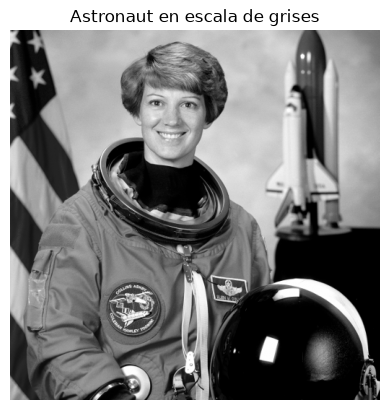

In [3]:
x = rgb2gray(img) # escala de grises

# ver dimesion y tipo 
print(f"x:", x.shape, "tipo:", x.dtype)

plt.imshow(x, cmap='gray')
plt.title("Astronaut en escala de grises")
plt.axis('off')
plt.savefig('astronaut_gray')
plt.show()

## 1.b Transformación a los dominios: Wavelet-2D, DCT-2D

In [4]:
# Aplicamos la descomposición Wavelet 2D
coeffs2 = pywt.wavedec2(x, wavelet='db4', level=3)

# Aplnamos todos los coeficientes para obtener theta
theta_wavelet, coeff_slices = pywt.coeffs_to_array(coeffs2)

print(f'Forma del vector:', theta_wavelet.shape)

theta_wavelet_vec = theta_wavelet.flatten()

print(f'Forma del vector:', theta_wavelet_vec.shape)

Forma del vector: (532, 532)
Forma del vector: (283024,)


In [ ]:
theta_dct = dctn(x, norm='ortho')
print(f'Forma del vector:', theta_dct.shape)
theta_dct_vec = np.asarray(theta_dct).flatten()

print(f'Forma del vector: {theta_dct_vec.shape}')

Forma del vector: (512, 512)
Forma del vector: (262144,)


### 1.c Grafico de los coeficientes de Theta vectorizados y ordenados

<function matplotlib.pyplot.show(close=None, block=None)>

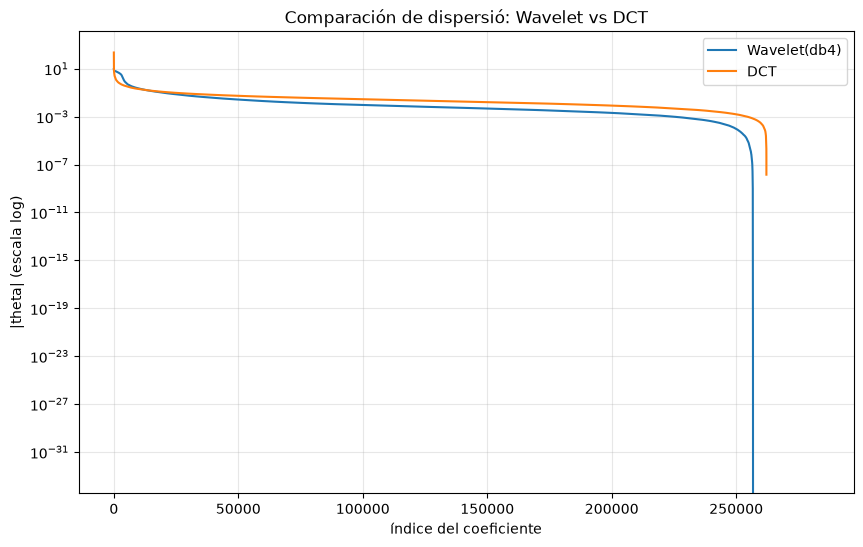

In [40]:
# Ordenar de mayor a menor
theta_wavelet_sorted = np.sort(np.abs(theta_wavelet_vec))[::-1]
theta_dct_sorted = np.sort(np.abs(theta_dct_vec))[::-1]

# Grafico

plt.figure(figsize=(10,6))
plt.plot(theta_wavelet_sorted, label = 'Wavelet(db4)')
plt.plot(theta_dct_sorted, label = 'DCT')
plt.yscale('log')
plt.xlabel('índice del coeficiente')
plt.ylabel('|theta| (escala log)')
plt.title('Comparación de dispersió: Wavelet vs DCT')
plt.legend()
plt.grid(True, alpha = 0.3)
plt.savefig('dispersion_coef')
plt.show

## 2.a Función de eliminacion de coeficientes

In [22]:
def delete_coeff(theta, P):
    theta_flat = np.asarray(theta).flatten()
    n = len(theta_flat)
    # encontrar umbral del k-esimo coef mas grande
    k = int(np.ceil(n*P / 100))
    idx_ordenados = np.argsort(np.abs(theta_flat))[::-1]
    idx_conservar = idx_ordenados[:k]

    theta_new = np.zeros_like(theta_flat)
    theta_new[idx_conservar] = theta_flat[idx_conservar]

    return theta_new.reshape(theta.shape)


## 2.c Reconstrucciones con distintos porcentajes ( 5, 10, 20, 50)

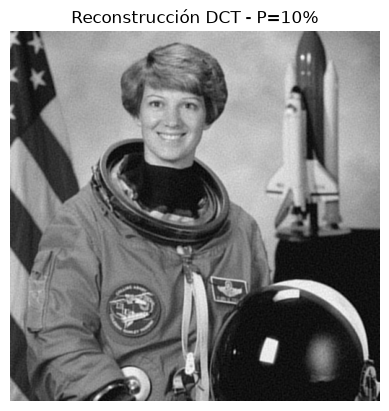

In [27]:
percentages = [5, 10, 20, 50]
reconst_dct = {}

for P in percentages:
    theta_dct_P = delete_coeff(theta_dct, P)
    x_hat_dct = idctn(theta_dct_P, norm='ortho')
    reconst_dct[P] = x_hat_dct
# Ejemplo: ver la reconstrucción con 10%
plt.imshow(reconst_dct[10], cmap='gray')
plt.title('Reconstrucción DCT - P=10%')
plt.axis('off')
plt.show()


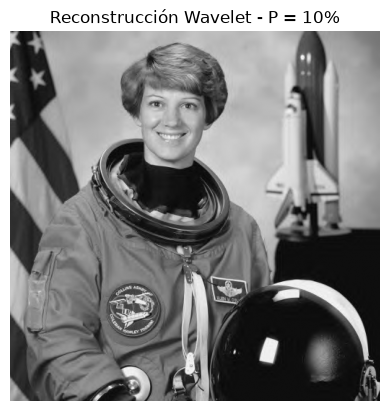

In [28]:
reconst_wavelet = {}

for P in percentages:
    theta_wavelet_P = delete_coeff(theta_wavelet, P)
    coeffs2_P = pywt.array_to_coeffs(theta_wavelet_P, coeff_slices, output_format='wavedec2')

    x_hat_wavelet = pywt.waverec2(coeffs2_P, wavelet='db4')
    reconst_wavelet[P] = x_hat_wavelet

plt.imshow(reconst_wavelet[10],cmap="gray")
plt.title('Reconstrucción Wavelet - P = 10%')
plt.axis('off')
plt.show()


## 2.d PSNR entre la original y cada reconstrucción.

In [37]:
psnr_dct = {}
psnr_wavelet={}

for P in percentages:
    # Para dct
    x_hat_dct = reconst_dct[P]
    psnr_dct[P] = psnr(x, x_hat_dct, data_range=x.max() - x.min())

    #Wavelet
    x_hat_wavelet = reconst_wavelet[P]
    if x_hat_wavelet.shape != x.shape:
        x_hat_wavelet = x_hat_wavelet[:x.shape[0], : x.shape[1]]
    psnr_wavelet[P] = psnr(x, x_hat_wavelet, data_range=x.max() - x.min())

print(f"{'P (%)':<8}{'PSNR DCT (dB)':<18}{'PSNR Wavelet (dB)':<18}")
for P in percentages:
    print(f"{P:<8}{psnr_dct[P]:<18.2f}{psnr_wavelet[P]:<18.2f}")


P (%)   PSNR DCT (dB)     PSNR Wavelet (dB) 
5       27.87             31.56             
10      30.52             37.07             
20      33.94             43.52             
50      42.28             54.98             


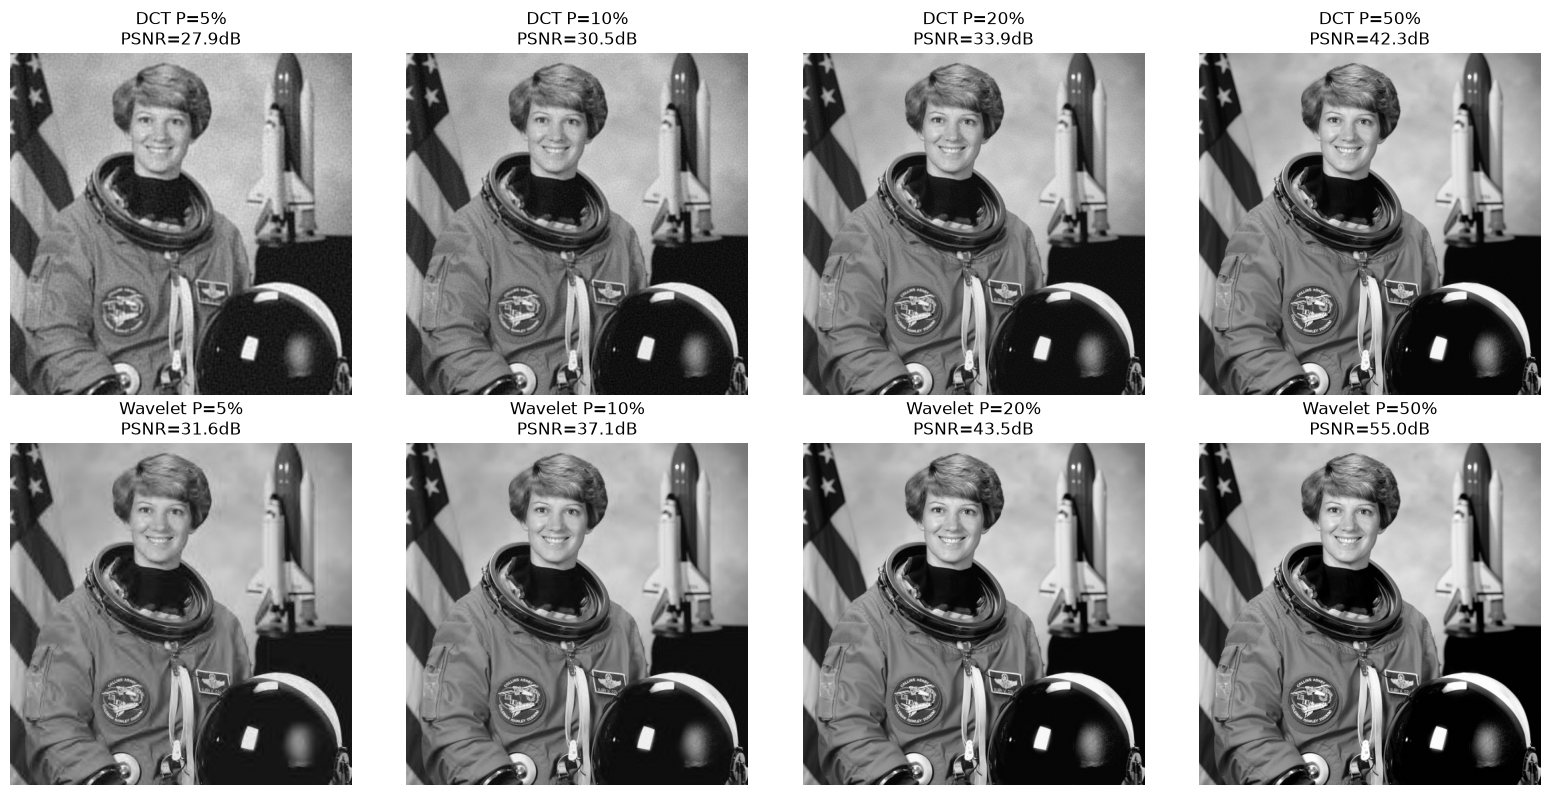

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, P in enumerate(percentages):
    axes[0, i].imshow(reconst_dct[P], cmap='gray')
    axes[0, i].set_title(f'DCT P={P}%\nPSNR={psnr_dct[P]:.1f}dB')
    axes[0, i].axis('off')
    
    axes[1, i].imshow(reconst_wavelet[P], cmap='gray')
    axes[1, i].set_title(f'Wavelet P={P}%\nPSNR={psnr_wavelet[P]:.1f}dB')
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('reconstruciones')
plt.show()

## 2.e ¿Cuál base representa de forma más dispersa cada imagen?, ¿cuál es el nivel de dispersión de cada imagen?

La Wavalet(db4), ya que para un mismo porcentaje de coeficientes conservados, en todos da mejor psnr(más alto) que la DCT, ya con un P igual a 50\% la diferencia es de casi 13 dB. esto significa que la Wavelet necesita menos coeficientes para lograr la misma calidad de reconstrucción que la DCT, es decir, concentrea mejor la energía de la imagen en pocos coeficientes grades. Lo que se respalda con el grafico de coeficientes ordenados, la curva de Wavelet tienede a caer más rápido hacia cero que la DCT.

La Wavelet alcanza un PSNR aceptable(35-40 dB) con solo el 10\% de los coeficientes, mientras que la DCT necesita bastante más (50\%) para acercase a esa calidad. En eso se puede observa el nivel de dispersión.